In [ ]:
# 22. Object Classification using VGG16 Transfer Learning 
# Develop an object classification model using Transfer Learning with the 
# pre-trained VGG16 architecture and the Caltech-101 dataset. Perform the 
# following steps: 
# a. Load the Caltech-101 dataset and select any 5 object categories for 
# classification. 
# b. Preprocess the images by resizing them to 224 × 224 pixels and 
# normalizing them using the VGG16 preprocessing function. 
# c. Load the pre-trained VGG16 model with ImageNet weights, excluding 
# its original classification layers. 
# d. Freeze all the pre-trained convolutional layers to retain the learned 
# image features. 
# e. Add a custom classifier consisting of GlobalAveragePooling2D, Dense, 
# Dropout and Softmax output layers. 
# f. Compile the model using the Adam optimizer and categorical 
# cross-entropy loss. 
# g. Train the custom classification layers and evaluate the model using test 
# images. 
# h. Display the test accuracy and predicted object categories for five 
# sample images. 

In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from PIL import Image
from sklearn.model_selection import train_test_split

from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input

from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.utils import to_categorical

In [3]:
dataset_path = r"C:\Users\prerna\Downloads\caltech101\101_ObjectCategories"

class_names = ['airplanes', 'Faces', 'Motorbikes', 'Leopards', 'car_side']

image_paths = []
labels = []

for label, category in enumerate(class_names):

    folder = os.path.join(dataset_path, category)

    for filename in os.listdir(folder):

        if filename.lower().endswith(('.jpg', '.jpeg', '.png')):

            image_paths.append(os.path.join(folder, filename))
            labels.append(label)

print("Total images:", len(image_paths))
print("Total categories:", len(class_names))
print("Categories:", class_names)

Total images: 2356
Total categories: 5
Categories: ['airplanes', 'Faces', 'Motorbikes', 'Leopards', 'car_side']


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    image_paths,
    labels,
    test_size=0.2,
    random_state=42,
    stratify=labels
)

y_train = to_categorical(y_train, num_classes=5)
y_test = to_categorical(y_test, num_classes=5)

print("Training images:", len(X_train))
print("Testing images:", len(X_test))

Training images: 1884
Testing images: 472


In [5]:
IMG_SIZE = 224

def preprocess_image(path, label):

    image = tf.io.read_file(path)

    image = tf.io.decode_image(
        image, channels=3, expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))

    image = preprocess_input(image)

    return image, label

In [6]:
BATCH_SIZE = 16

train_ds = tf.data.Dataset.from_tensor_slices(
    (X_train, y_train)
)

train_ds = train_ds.map(
    preprocess_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

train_ds = train_ds.shuffle(1000).batch(BATCH_SIZE).prefetch(
    tf.data.AUTOTUNE
)


test_ds = tf.data.Dataset.from_tensor_slices(
    (X_test, y_test)
)

test_ds = test_ds.map(
    preprocess_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_ds = test_ds.batch(BATCH_SIZE).prefetch(
    tf.data.AUTOTUNE
)

print("Training and testing datasets created!")

Training and testing datasets created!


In [7]:
base_model = VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

print("VGG16 model loaded successfully!")

VGG16 model loaded successfully!


In [8]:
x = base_model.output

x = GlobalAveragePooling2D()(x)

x = Dense(256, activation='relu')(x)

x = Dropout(0.5)(x)

output = Dense(5, activation='softmax')(x)

model = Model(
    inputs=base_model.input,
    outputs=output
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_conv1 (Conv2D)                │ (None, 224, 224, 64)        │           1,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_conv2 (Conv2D)                │ (None, 224, 224, 64)        │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_pool (MaxPooling2D)           │ (None, 112, 112, 64)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_conv1 (Conv2D)                │ (None, 112, 112, 128)       │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_conv2 (Conv2D)                │ (None, 112, 112, 128)       │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_pool (MaxPooling2D)           │ (None, 56, 56, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv1 (Conv2D)                │ (None, 56, 56, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv2 (Conv2D)                │ (None, 56, 56, 256)         │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv3 (Conv2D)                │ (None, 56, 56, 256)         │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_pool (MaxPooling2D)           │ (None, 28, 28, 256)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv1 (Conv2D)                │ (None, 28, 28, 512)         │       1,180,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv2 (Conv2D)                │ (None, 28, 28, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv3 (Conv2D)                │ (None, 28, 28, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_pool (MaxPooling2D)           │ (None, 14, 14, 512)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv1 (Conv2D)                │ (None, 14, 14, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv2 (Conv2D)                │ (None, 14, 14, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv3 (Conv2D)                │ (None, 14, 14, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_pool (MaxPooling2D)           │ (None, 7, 7, 512)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 512)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 256)                 │         131,3

 Total params: 14,847,301 (56.64 MB)

 Trainable params: 132,613 (518.02 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [9]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully!")

Model compiled successfully!


In [10]:
history = model.fit(
    train_ds,
    epochs=5
)

Epoch 1/5


C:\Users\prerna\AppData\Roaming\Python\Python314\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


118/118 ━━━━━━━━━━━━━━━━━━━━ 291s 2s/step - accuracy: 0.9591 - loss: 0.2469
Epoch 2/5
118/118 ━━━━━━━━━━━━━━━━━━━━ 282s 2s/step - accuracy: 0.9968 - loss: 0.0086
Epoch 3/5
118/118 ━━━━━━━━━━━━━━━━━━━━ 283s 2s/step - accuracy: 0.9995 - loss: 0.0026
Epoch 4/5
118/118 ━━━━━━━━━━━━━━━━━━━━ 281s 2s/step - accuracy: 1.0000 - loss: 5.1347e-04
Epoch 5/5
118/118 ━━━━━━━━━━━━━━━━━━━━ 283s 2s/step - accuracy: 0.9973 - loss: 0.0064


In [11]:
test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Loss:", test_loss)

print("Test Accuracy:", test_accuracy * 100, "%")

30/30 ━━━━━━━━━━━━━━━━━━━━ 72s 2s/step - accuracy: 1.0000 - loss: 9.9433e-04
Test Loss: 0.0009943339973688126
Test Accuracy: 100.0 %


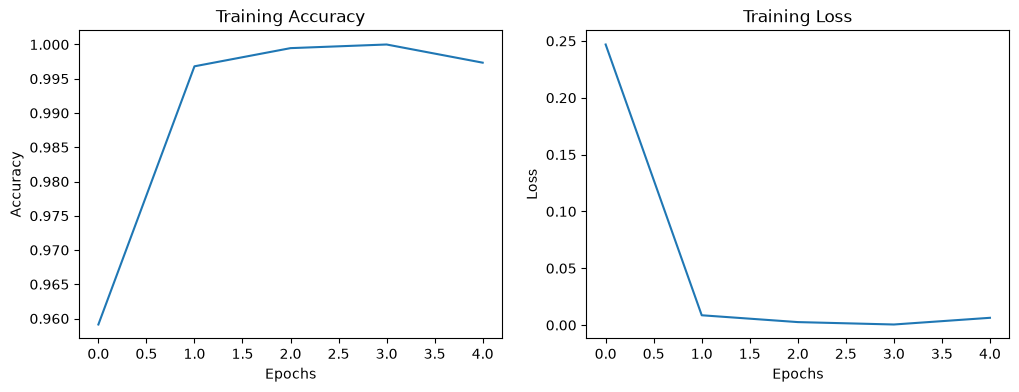

In [12]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'])
plt.title('Training Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'])
plt.title('Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')

plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


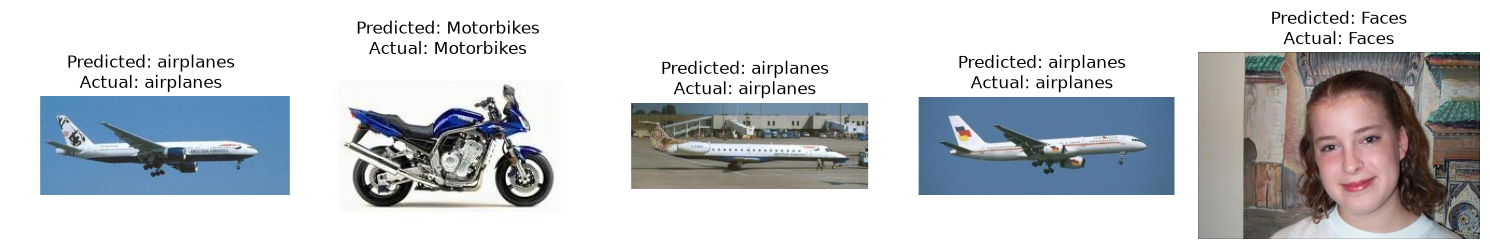

Five sample predictions completed!


In [13]:
sample_paths = X_test[:5]

sample_images = []

for path in sample_paths:

    img = Image.open(path).convert('RGB')
    img = img.resize((224, 224))

    img_array = np.array(img, dtype=np.float32)

    img_array = preprocess_input(img_array)

    sample_images.append(img_array)

sample_images = np.array(sample_images)

predictions = model.predict(sample_images)

plt.figure(figsize=(15, 5))

for i in range(5):

    predicted_class = class_names[np.argmax(predictions[i])]

    actual_class = class_names[np.argmax(y_test[i])]

    plt.subplot(1, 5, i + 1)

    img = Image.open(sample_paths[i]).convert('RGB')

    plt.imshow(img)

    plt.title(
        f"Predicted: {predicted_class}\nActual: {actual_class}"
    )

    plt.axis('off')

plt.tight_layout()
plt.show()

print("Five sample predictions completed!")